# MATPLOTLIB MASTERY — NOTEBOOK 6
## Chapters 46–55: Heatmaps → Images/Matrices → Colorbars → Contour Plots → 3D Visualization → ML Visualization Intro → Classification Visualization → Confusion Matrix → ROC Curve → Precision-Recall Curve

Continuing directly from Notebook 5. This notebook begins the dedicated **Machine Learning visualization** block of the course and uses `scikit-learn` to train small real models so every ML chart is built from a genuine model, not simulated numbers.

### Progress Tracker (this notebook)
- [x] Chapter 46 — Heatmap with Matplotlib
- [x] Chapter 47 — Images and Matrices
- [x] Chapter 48 — Colorbars
- [x] Chapter 49 — Contour Plots
- [x] Chapter 50 — 3D Visualization
- [x] Chapter 51 — Machine Learning Visualization (Overview)
- [x] Chapter 52 — Classification Model Visualization
- [x] Chapter 53 — Confusion Matrix From Scratch
- [x] Chapter 54 — ROC Curve
- [x] Chapter 55 — Precision-Recall Curve


In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
np.random.seed(42)


---
# CHAPTER 46 — HEATMAP WITH MATPLOTLIB

## 1. Concept
A heatmap renders a 2D matrix as a grid of colored cells, where color encodes each cell's numeric value — built in pure Matplotlib via `ax.imshow()` (Chapter 45 already used this for a correlation matrix; this chapter generalizes the technique to any matrix).

## 2. Why It Matters
Heatmaps are the standard visualization for anything naturally shaped as a matrix: correlation matrices, confusion matrices (Chapter 53), pivot-table cross-tabulations, and attention/activation matrices in deep learning.

## 3–4. NumPy / Pandas Connection
`ax.imshow(pivot_table.values)` — any 2D NumPy array or Pandas DataFrame (via `.values`) plugs in directly; row/column labels come from the DataFrame's index/columns.


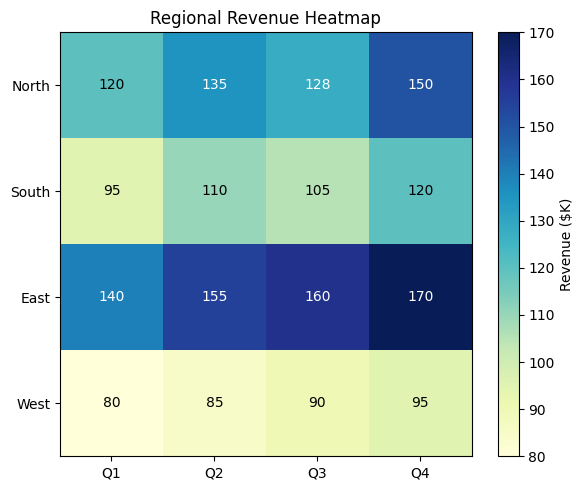

In [2]:
sales_pivot = pd.DataFrame(
    np.array([
        [120, 135, 128, 150],
        [95, 110, 105, 120],
        [140, 155, 160, 170],
        [80, 85, 90, 95],
    ]),
    index=["North", "South", "East", "West"],
    columns=["Q1", "Q2", "Q3", "Q4"],
)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sales_pivot.values, cmap="YlGnBu", aspect="auto")

ax.set_xticks(range(len(sales_pivot.columns)))
ax.set_yticks(range(len(sales_pivot.index)))
ax.set_xticklabels(sales_pivot.columns)
ax.set_yticklabels(sales_pivot.index)

for i in range(sales_pivot.shape[0]):
    for j in range(sales_pivot.shape[1]):
        ax.text(j, i, sales_pivot.values[i, j], ha="center", va="center",
                color="white" if sales_pivot.values[i, j] > sales_pivot.values.mean() else "black")

fig.colorbar(im, ax=ax, label="Revenue ($K)")
ax.set_title("Regional Revenue Heatmap")
plt.tight_layout()
plt.show()


### Parameter Explanation
- `cmap="YlGnBu"` — a **sequential** colormap (Chapter 7), appropriate here since revenue has a natural low→high ordering with no meaningful "zero-centered" midpoint (unlike the correlation matrix in Chapter 45, which needed a diverging map).
- `aspect="auto"` — stretches cells to fill the Axes rectangle regardless of the matrix's row/column count ratio; the alternative, `aspect="equal"` (default), forces perfectly square cells, which can leave large empty margins for non-square matrices.
- The color-vs-mean text-color logic mirrors Chapter 45's pattern: keep annotation text legible against both light and dark cells.

### Interpretation
East region leads every quarter, while West consistently trails — a heatmap makes this dual pattern (best-performing row, worst-performing row, and their consistency across all four columns) immediately visible in a way that scanning a 4×4 numeric table would not.

### Common Mistakes
- Using a diverging colormap for a matrix with no meaningful zero midpoint (like this revenue matrix) — implies a "positive vs negative" contrast that doesn't apply here; sequential is correct.
- Forgetting `aspect="auto"` on non-square matrices, resulting in an awkwardly tiny or oddly-proportioned heatmap.

### Best Practices
- Match colormap type (sequential vs diverging) to whether the underlying quantity has a meaningful zero/center point — the same rule from Chapter 7, applied consistently to every heatmap you build.
- Annotate cell values directly whenever the matrix is small enough to remain legible (same guidance as Chapter 45).

### Interview Insight
**Q: How would you build a heatmap in pure Matplotlib (no Seaborn), and what determines your colormap choice?**
A: `ax.imshow()` on the matrix's underlying NumPy array, with manually set tick positions/labels from the DataFrame's index/columns, plus `fig.colorbar()` for the scale reference. Colormap choice follows the same sequential-vs-diverging logic as any other color encoding (Chapter 7): sequential for a matrix with a natural low-to-high ordering and no meaningful center, diverging for one centered meaningfully around zero (like correlation).

### Mini Exercise
Rebuild the heatmap with `cmap="coolwarm"` instead of `"YlGnBu"` and discuss, in a markdown cell, why it's a worse choice for this specific (non-zero-centered) revenue data.

### Quiz (Chapter 46)
1. What Matplotlib function is the core primitive behind any heatmap?
2. What determines whether a heatmap should use a sequential or diverging colormap?
3. What does `aspect="auto"` change about the rendered heatmap?


---
# CHAPTER 47 — IMAGES AND MATRICES

## 1. Concept
`ax.imshow()` is fundamentally an **image renderer** — a heatmap (Chapter 46) is just one specific use of it. The same function displays actual photographs, confusion matrices, correlation matrices, and any 2D (or 3D, for RGB) NumPy array.

## 2. Why It Matters
Understanding `imshow()`'s core parameters (`interpolation`, `aspect`, `origin`, `cmap`) is essential across a surprising range of ML/DS work: viewing raw image data, visualizing convolutional filter outputs, and building any custom matrix-based diagnostic (like the confusion matrix in Chapter 53).


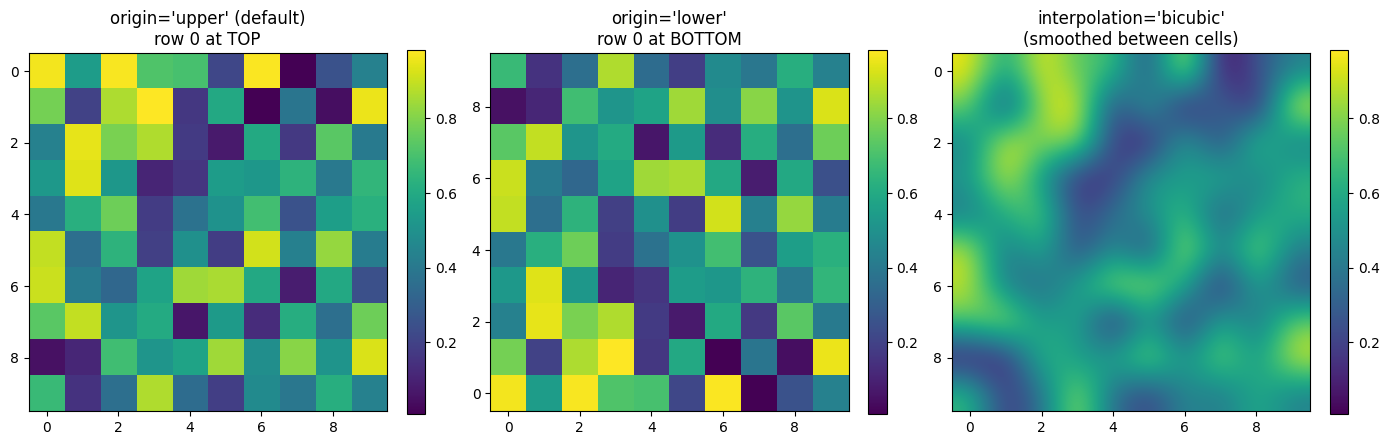

In [3]:
np.random.seed(4)
matrix_47 = np.random.rand(10, 10)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

im0 = axes[0].imshow(matrix_47, cmap="viridis", origin="upper")
axes[0].set_title("origin='upper' (default)\nrow 0 at TOP")

im1 = axes[1].imshow(matrix_47, cmap="viridis", origin="lower")
axes[1].set_title("origin='lower'\nrow 0 at BOTTOM")

im2 = axes[2].imshow(matrix_47, cmap="viridis", interpolation="bicubic")
axes[2].set_title("interpolation='bicubic'\n(smoothed between cells)")

for ax, im in zip(axes, [im0, im1, im2]):
    fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `origin` | `'upper'` (default — row 0 at the top, matching how a matrix is usually printed/read) vs `'lower'` (row 0 at the bottom, matching standard Cartesian y-axis convention — important for correctly orienting scientific/mathematical matrices) |
| `interpolation` | `'nearest'` (default-like, sharp cell boundaries — correct for a confusion/correlation matrix where each cell is a discrete, exact value) vs `'bicubic'`/`'bilinear'` (smoothed — correct for actual photographic images, wrong for exact-value matrices, since smoothing fabricates in-between values that don't exist) |
| `aspect` | `'equal'` (square cells, default) vs `'auto'` (stretch to fill) |
| `cmap` | Only applies to single-channel (2D) arrays; a 3D array with shape `(H, W, 3)` or `(H, W, 4)` is interpreted directly as RGB(A) and `cmap` is ignored entirely |
| `vmin`/`vmax` | Explicit color-scale bounds (Chapter 45's fixed-range pattern) |

### Critical Rule: Never Interpolate a Confusion/Correlation Matrix
Applying `interpolation='bicubic'` to a confusion matrix or correlation matrix (any matrix of **exact, discrete** values) visually fabricates smoothed transitions between cells that don't correspond to any real intermediate value — actively misleading. Interpolation smoothing is appropriate **only** for genuine continuous-valued images (like photographs or scientific field data), never for tables of discrete exact numbers being displayed as a matrix.

### Interpretation
`origin='lower'` matters specifically whenever a matrix represents something with an inherent bottom-to-top physical or mathematical meaning (e.g., a spatial field, a scientific measurement grid) — using the wrong origin silently flips the data vertically, which can invert an otherwise-correct scientific conclusion if unnoticed.

### Common Mistakes
- Applying smoothing interpolation to a discrete-value matrix (confusion matrix, correlation matrix, categorical crosstab) — fabricates false precision between cells.
- Using the default `origin='upper'` for genuinely spatial/Cartesian data that conventionally has its origin at the bottom-left — silently flips the visualization.
- Forgetting that `cmap` is silently ignored for already-RGB(A) 3D arrays, then being confused why a `cmap=` argument "does nothing."

### Best Practices
- Use `interpolation='nearest'` (or leave default) for any matrix of exact, discrete values.
- Explicitly set `origin` deliberately rather than relying on the default, whenever the matrix has an inherent spatial/mathematical orientation.

### Interview Insight
**Q: Why should you never use `interpolation='bicubic'` when displaying a confusion matrix?**
A: Bicubic interpolation smooths color transitions *between* adjacent cells, visually implying intermediate values that don't actually exist — a confusion matrix's cells are exact discrete counts, and smoothing them fabricates false precision/gradients that could mislead someone reading the chart into perceiving relationships between cells that aren't really there. `interpolation='nearest'` (sharp cell boundaries) is the only appropriate choice for exact-value matrices.

### Mini Exercise
Load or construct a small 3-channel RGB array (`np.random.rand(20, 20, 3)`) and confirm that passing `cmap="viridis"` to `ax.imshow()` on it has no visible effect, unlike on the single-channel `matrix_47` example above.

### Quiz (Chapter 47)
1. What's the difference between `origin='upper'` and `origin='lower'`, and when does it matter?
2. Why is interpolation smoothing dangerous specifically for confusion/correlation matrices?
3. When does the `cmap` parameter get silently ignored?


---
# CHAPTER 48 — COLORBARS

## 1. Concept
`fig.colorbar(mappable, ax=ax)` draws the color-to-value legend for any color-mapped Artist (`imshow`, `scatter` with `c=`, `contourf`) — without it, a color-encoded chart has no way for the reader to translate color back into an actual number.

## 2. Why It Matters
Any time color encodes a continuous variable (Chapter 7), a colorbar is **not optional** — it's the legend for that entire encoding channel, exactly as essential as `ax.legend()` is for labeled lines.


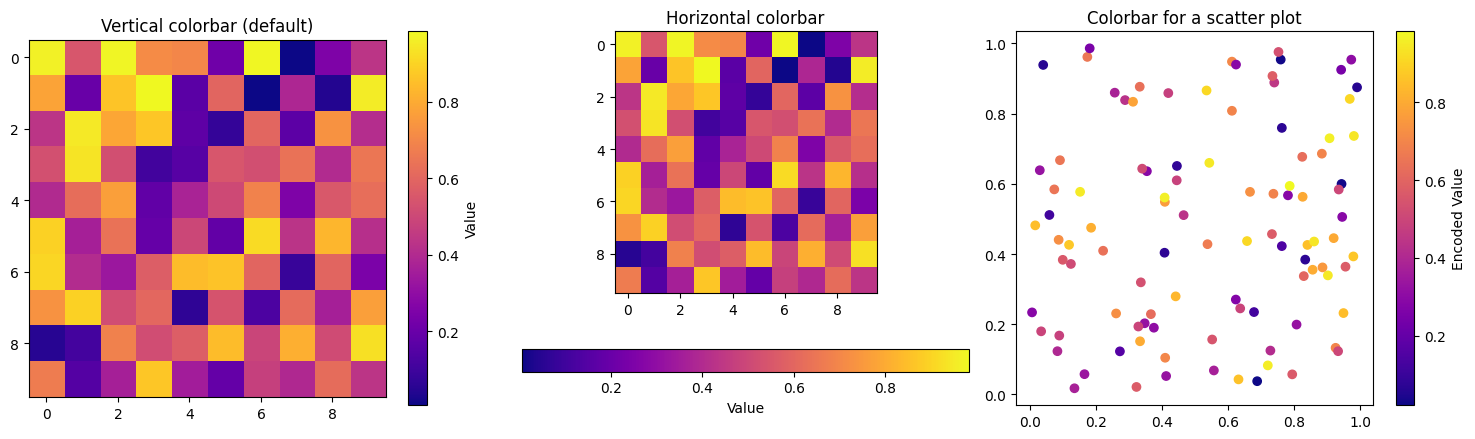

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

im0 = axes[0].imshow(matrix_47, cmap="plasma")
cbar0 = fig.colorbar(im0, ax=axes[0], orientation="vertical")
cbar0.set_label("Value")
axes[0].set_title("Vertical colorbar (default)")

im1 = axes[1].imshow(matrix_47, cmap="plasma")
cbar1 = fig.colorbar(im1, ax=axes[1], orientation="horizontal", pad=0.15)
cbar1.set_label("Value")
axes[1].set_title("Horizontal colorbar")

sc = axes[2].scatter(np.random.rand(100), np.random.rand(100), c=np.random.rand(100), cmap="plasma")
cbar2 = fig.colorbar(sc, ax=axes[2])
cbar2.set_label("Encoded Value")
axes[2].set_title("Colorbar for a scatter plot")

plt.tight_layout()
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `mappable` | The colored Artist to build the legend for — the object returned by `imshow()`, `scatter()`, or `contourf()` |
| `ax` | Which Axes to attach the colorbar next to (steals a slice of that Axes' space) |
| `orientation` | `'vertical'` (default) or `'horizontal'` |
| `label` (via `.set_label()`) | Describes what the color/value represents — as essential as an axis label |
| `pad` | Spacing between the colorbar and its parent Axes |
| `shrink` / `fraction` | Control the colorbar's relative size — useful to prevent an oversized colorbar from dominating a small subplot |

### Internal Working
`fig.colorbar()` doesn't just draw a decorative gradient bar — it creates a genuine new (thin) `Axes` object, mapped through the *same* `Normalize` + colormap instance that the original Artist used, guaranteeing the bar's gradient exactly matches the plotted colors' true value mapping.

### Common Mistakes
- Color-encoding data (via `c=` or `imshow`) with **no colorbar at all** — the single most common omission in ML/DS notebooks, leaving color meaningless to the reader.
- Forgetting `.set_label()` — a colorbar with numbers but no description of *what* those numbers represent is only marginally better than no colorbar.
- Attaching a colorbar to the wrong subplot's `ax=` in a multi-panel figure with multiple independently-color-mapped panels — each panel needs its **own** colorbar if their color scales differ, but a single shared colorbar is correct (and preferred, to save space) if all panels share the exact same `vmin`/`vmax`.

### Best Practices
- Treat a colorbar as mandatory, not optional, wherever color encodes a continuous variable — no exceptions.
- Always label it.
- For a grid of subplots sharing an identical color scale, use one shared colorbar for the whole figure rather than repeating it per panel (cleaner and reinforces that the scale is shared).

### Interview Insight
**Q: You built a scatter plot with `c=some_continuous_array`, but no colorbar. What's wrong with shipping this chart as-is?**
A: Color is being used as a full encoding channel for a continuous variable, exactly like a y-axis encodes a numeric value — without a colorbar, the reader has no way to translate a point's color back into an actual number, making that entire dimension of the chart uninterpretable. `fig.colorbar(sc, ax=ax, label=...)` is a required companion to any continuous color mapping, not an optional polish step.

### Mini Exercise
Build a 1×2 subplot where both panels use `imshow()` on different matrices but with the same explicit `vmin=0, vmax=1`, and attach a **single shared colorbar** for both (`fig.colorbar(im, ax=axes.tolist())`) instead of one per panel.

### Quiz (Chapter 48)
1. Why is a colorbar not optional whenever color encodes a continuous variable?
2. What guarantees a colorbar's gradient exactly matches its Artist's actual color mapping?
3. When is it appropriate to use one shared colorbar across multiple subplots?


---
# CHAPTER 49 — CONTOUR PLOTS

## 1. Concept
`ax.contour()` draws lines connecting points of **equal value** across a 2D surface (like elevation contour lines on a topographic map); `ax.contourf()` (filled contour) shades the regions between those lines instead of just outlining them.

## 2. Why It Matters
Contour plots visualize a function of **two input variables** producing one output — directly applicable to ML decision boundaries (does the model predict class 0 or class 1 across the full 2D feature space?) and optimization landscapes (loss surface across two hyperparameters).


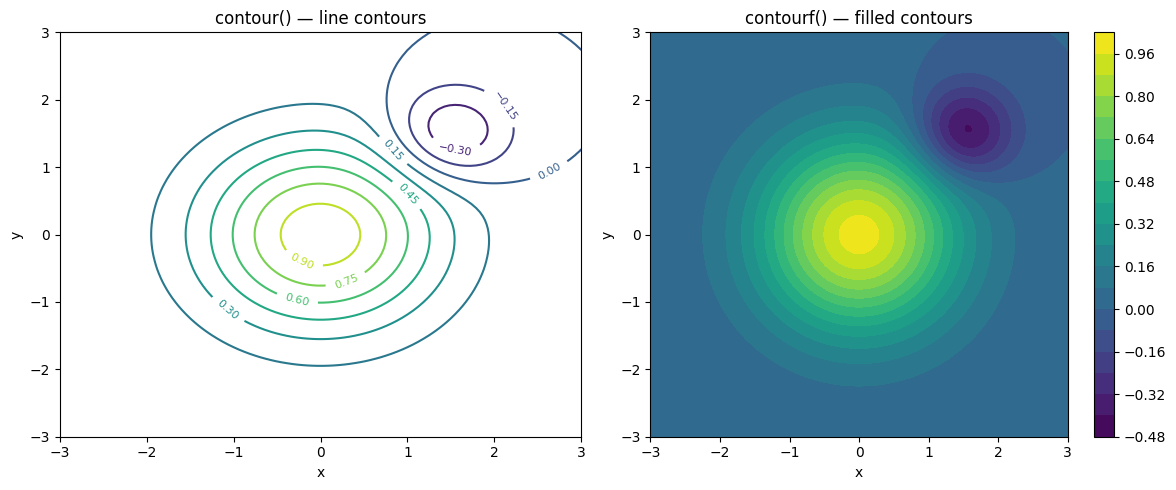

In [5]:
x_grid = np.linspace(-3, 3, 100)
y_grid = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x_grid, y_grid)
Z = np.exp(-(X**2 + Y**2) / 2) - 0.5 * np.exp(-((X - 1.5)**2 + (Y - 1.5)**2) / 0.5)   # a bumpy 2-peak surface

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cs = axes[0].contour(X, Y, Z, levels=12, cmap="viridis")
axes[0].clabel(cs, inline=True, fontsize=8)
axes[0].set_title("contour() — line contours")

cf = axes[1].contourf(X, Y, Z, levels=20, cmap="viridis")
fig.colorbar(cf, ax=axes[1])
axes[1].set_title("contourf() — filled contours")

for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `np.meshgrid(x_grid, y_grid)` — the essential NumPy step: converts two 1D coordinate arrays into two 2D arrays (`X`, `Y`) representing every combination of x and y across the grid — required input shape for both `contour()` and `contourf()`, and for `ax.imshow()`-style surface functions generally.
- `Z = f(X, Y)` — evaluate the function of interest (here, a synthetic two-peak surface) at every grid point simultaneously, via vectorized NumPy operations on the full 2D arrays.
- `levels=12` — the number of contour lines/filled bands to draw; more levels = finer resolution of the surface's shape, at the cost of visual density.
- `ax.clabel(cs, inline=True)` — labels each contour line directly with its value, breaking the line to insert the label text (`inline=True`) rather than placing it off to the side.

### Internal Working
Both functions triangulate the `Z` surface between grid points and either trace iso-value lines (`contour`) or fill the bands between consecutive `levels` thresholds with color (`contourf`) — conceptually the 2D analogue of how a histogram bins a 1D distribution into intervals.

### ML Application: Visualizing a Decision Boundary
A classification model's decision boundary is exactly a contour line: the specific curve in feature space where the model's predicted probability crosses 0.5 (or its predicted class flips). This technique becomes central again in Chapter 52.

### Common Mistakes
- Forgetting `np.meshgrid()` and passing raw 1D `x`/`y` arrays directly to `contour()` — raises a shape-mismatch error, since `contour`/`contourf` require full 2D coordinate grids, not 1D axes arrays.
- Using too few `levels` for a surface with fine structure — loses genuine detail; too many can create visual clutter of near-identical shades.
- Confusing `contour` (outlines only, fast, good for overlaying on top of another chart) with `contourf` (filled, best as a standalone surface visualization) and using the wrong one for the intended purpose.

### Best Practices
- Use `contourf` + colorbar as the primary surface visualization; overlay `contour` with `clabel` on top when specific labeled threshold lines are also useful.
- Always build the coordinate grid via `np.meshgrid()` before evaluating any 2-input function for contour plotting.

### Interview Insight
**Q: How would you visualize a trained classifier's decision boundary across a 2D feature space?**
A: Build a fine `np.meshgrid()` covering the feature space's range, call `model.predict()` (or `.predict_proba()`) on every grid point (reshaped appropriately), reshape the resulting predictions back into the grid's 2D shape as `Z`, then use `ax.contourf(X, Y, Z)` to shade each region by predicted class — the boundary between filled regions **is** the decision boundary. Overlaying the actual training points as a scatter on top completes the visualization.

### Mini Exercise
Increase `levels` to 40 and observe how much finer the surface's two-peak structure becomes resolved, compared to `levels=12`.

### Quiz (Chapter 49)
1. What NumPy function is required to build the input grid for `contour`/`contourf`?
2. What's the conceptual difference between `contour` and `contourf`?
3. How does a contour plot relate directly to a classifier's decision boundary?


---
# CHAPTER 50 — 3D VISUALIZATION

## 1. Concept
`from mpl_toolkits.mplot3d import Axes3D` (imported for its side effect of registering the `'3d'` projection) enables `fig.add_subplot(projection='3d')`, unlocking `ax.scatter3D()`, `ax.plot3D()`, and `ax.plot_surface()`.

## 2. Why It Matters — and When NOT to Use 3D
3D plots let you visualize a genuine 3-numerical-variable relationship directly, but they come with a serious, well-documented cost: **occlusion** (points/surfaces block each other) and **perspective distortion** (equal-magnitude differences look unequal depending on depth/angle) make precise reading much harder than an equivalent 2D chart (e.g., a contour plot or small multiples). Use 3D sparingly, and prefer it for **exploratory rotation in an interactive environment**, not for a single static image meant to convey precise values.


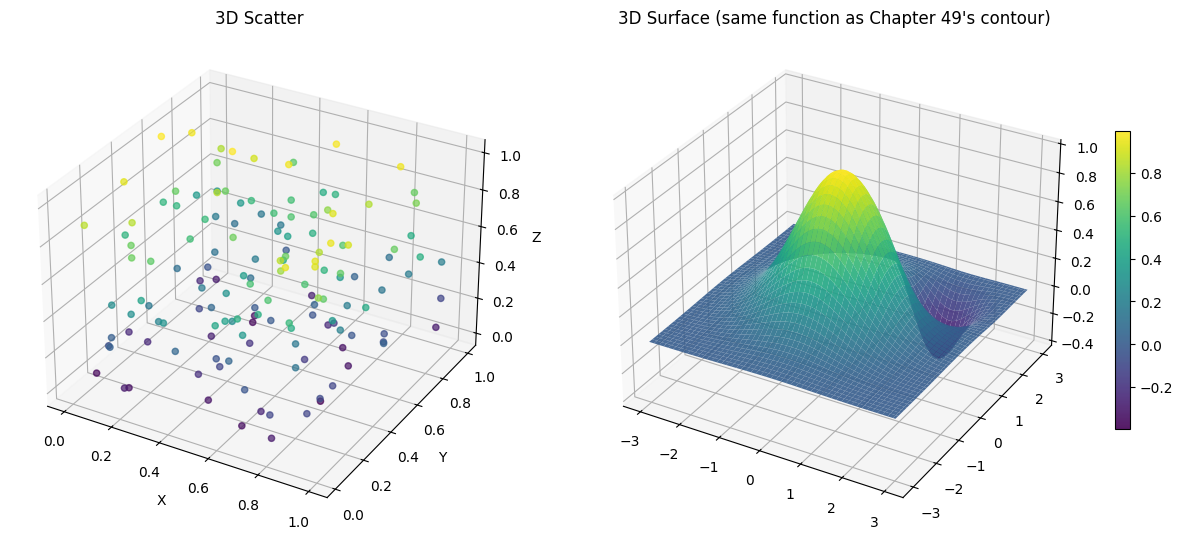

In [6]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 -- registers the 3D projection

fig = plt.figure(figsize=(13, 5.5))

# 3D scatter
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
n_pts = 150
x3, y3, z3 = np.random.rand(n_pts), np.random.rand(n_pts), np.random.rand(n_pts)
ax1.scatter(x3, y3, z3, c=z3, cmap="viridis", alpha=0.7)
ax1.set_title("3D Scatter")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")

# 3D surface (reusing the meshgrid Z surface from Chapter 49)
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
surf = ax2.plot_surface(X, Y, Z, cmap="viridis", edgecolor="none", alpha=0.9)
ax2.set_title("3D Surface (same function as Chapter 49's contour)")
fig.colorbar(surf, ax=ax2, shrink=0.6)

plt.tight_layout()
plt.show()


### Parameter Explanation
- `projection="3d"` — the key argument turning a regular `Axes` into an `Axes3D`, unlocking the extra z-dimension API.
- `ax.set_zlabel()` — the 3rd-axis analogue of `set_xlabel`/`set_ylabel`.
- `ax.plot_surface(X, Y, Z, ...)` — takes the exact same `meshgrid`-built `X`, `Y`, `Z` arrays as `contourf()` did in Chapter 49, demonstrating directly that a 3D surface and a 2D filled contour plot are **two different renderings of identical underlying data** — worth comparing side by side to judge which communicates the surface's shape more precisely for a given audience.

### Interpretation: Compare This Surface to Chapter 49's Contour of the SAME Function
The 3D surface intuitively conveys "peaks and valleys" in a way that feels immediately natural — but precisely reading off, say, "what's the Z value at (x=1, y=1)?" is genuinely harder from the 3D view (due to occlusion and perspective) than from the 2D filled contour, where you can read the exact color band or interpolate between labeled contour lines. This is the core, general tradeoff of 3D visualization: intuitive first impression vs. precise readability.

### Common Mistakes
- Defaulting to 3D for any 3-variable relationship without considering that a 2D approach (contour plot, or a 2D scatter with the 3rd variable as color/size — Chapters 13–14) is very often more precisely readable in a static image.
- Using 3D bar charts (mentioned back in Chapter 15) — combines 3D's perspective distortion with bars' length-based magnitude encoding in the worst possible way; virtually always worse than an equivalent 2D grouped or heatmap-style visualization.
- Presenting a static, non-rotatable 3D plot in a report/paper where the "best" viewing angle happens to occlude the most important part of the data — always choose (or allow interactive rotation to find) an angle that doesn't hide the key insight.

### Best Practices
- Reserve 3D specifically for genuinely exploratory, interactive contexts (a live notebook where the audience can rotate the view) rather than static report figures.
- For a static deliverable, default to 2D alternatives (contour/heatmap, or 2D scatter with color/size as the 3rd dimension) whenever precise value-reading matters more than an intuitive "shape" impression.

### Interview Insight
**Q: A colleague wants a 3D surface plot for a report PDF (static, non-interactive). What would you suggest instead, and why?**
A: A 2D filled contour plot (`contourf`) with a colorbar, built from the exact same `meshgrid`-evaluated data — it avoids the occlusion and perspective-distortion problems inherent to a static 3D rendering, and lets a reader precisely read off values via color/contour-line position, which a fixed-angle 3D image cannot offer without interactivity.

### Mini Exercise
Change `ax2.view_init(elev=20, azim=45)` (add this call after creating `ax2`) to rotate the 3D surface to a different fixed viewing angle, and observe how much the perceived shape of the surface changes purely from the choice of camera angle — with no change to the underlying data.

### Quiz (Chapter 50)
1. What two specific problems make static 3D plots harder to read precisely than their 2D equivalents?
2. When is 3D visualization still a reasonable choice?
3. Why are 3D bar charts specifically discouraged?


---
# CHAPTER 51 — MACHINE LEARNING VISUALIZATION (OVERVIEW)

## 1. Concept
This chapter is a bridge: every Matplotlib primitive from Notebooks 1–5 (lines, scatter, bars, heatmaps, fill_between) now gets applied specifically to the **model development lifecycle** — training, evaluation, comparison, and diagnosis.

## The ML Visualization Map
| Stage | Visualization | Chapter |
|---|---|---|
| During training | Training/validation curves | Ch 4 (already covered) |
| Classification evaluation | Confusion matrix, ROC, Precision-Recall | Ch 52–55 |
| Regression evaluation | Actual vs predicted, residuals | Ch 57–58 |
| Feature understanding | Feature importance | Ch 59 |
| Model comparison | Grouped bar of metrics | Ch 17 (already covered), Ch 60 |
| Tuning | Hyperparameter curves, learning curves | Ch 61–63 |
| Post-deployment | Error analysis, data drift | Ch 65–67 |

## Setting Up a Real Model for the Rest of This Notebook
We'll train an actual `scikit-learn` classifier on a synthetic dataset so that Chapters 52–55's charts are built from genuine model output, not hand-simulated numbers.


In [7]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

X, y = make_classification(
    n_samples=1000, n_features=10, n_informative=6, n_redundant=2,
    weights=[0.75, 0.25],   # imbalanced, like the churn scenario from Notebook 5
    random_state=42,
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

log_reg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
rf_clf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
y_proba_lr = log_reg.predict_proba(X_test)[:, 1]     # probability of the positive class
y_pred_rf = rf_clf.predict(X_test)
y_proba_rf = rf_clf.predict_proba(X_test)[:, 1]

print("Test set size:", len(y_test))
print("Positive class rate in test set:", y_test.mean().round(3))
print("Logistic Regression accuracy:", (y_pred_lr == y_test).mean().round(3))
print("Random Forest accuracy:", (y_pred_rf == y_test).mean().round(3))


Test set size: 300
Positive class rate in test set: 0.253
Logistic Regression accuracy: 0.803
Random Forest accuracy: 0.92


### Why This Setup Matters
- **`weights=[0.75, 0.25]`** — deliberately imbalanced, exactly like real churn/fraud/rare-event data, so the upcoming Precision-Recall chapter's core lesson (why PR curves matter more than ROC under imbalance) has genuine data to demonstrate on.
- **Two models trained** (`log_reg`, `rf_clf`) — enables real model-comparison charts, not synthetic placeholders.
- **`predict_proba()[:, 1]`** — the probability of the *positive* class, the raw input every threshold-based visualization (ROC, PR, threshold analysis) requires; `predict()` alone (a fixed 0.5-threshold decision) is not enough for these charts.

### Interview Insight
**Q: Why do ROC and Precision-Recall curve visualizations require `predict_proba()` output rather than just `predict()`?**
A: `predict()` only returns the final class decision at a single, fixed implicit threshold (usually 0.5) — it discards the information needed to see how the model's precision/recall/TPR/FPR trade off as that threshold varies. `predict_proba()` provides the raw probability scores, from which any threshold's resulting confusion matrix (and therefore any point on the ROC or PR curve) can be recomputed.

### Quiz (Chapter 51)
1. Why was the synthetic dataset deliberately built with class imbalance?
2. What model output is required for ROC/PR curves that `.predict()` alone doesn't provide?
3. Name the ML lifecycle stage each of these belongs to: training curves, confusion matrix, feature importance, hyperparameter tuning curves.


---
# CHAPTER 52 — CLASSIFICATION MODEL VISUALIZATION

## 1. Concept
Beyond the confusion matrix/ROC/PR curves (their own dedicated chapters), classification diagnostics also include: the raw **predicted probability distribution** (split by true class) and a **threshold-performance sweep** — both built from the exact same `predict_proba()` output established in Chapter 51.

## 2. Why It Matters
A single accuracy number hides *how* a model is wrong and *how confident* it is when right vs. wrong — the probability distribution view directly exposes both.


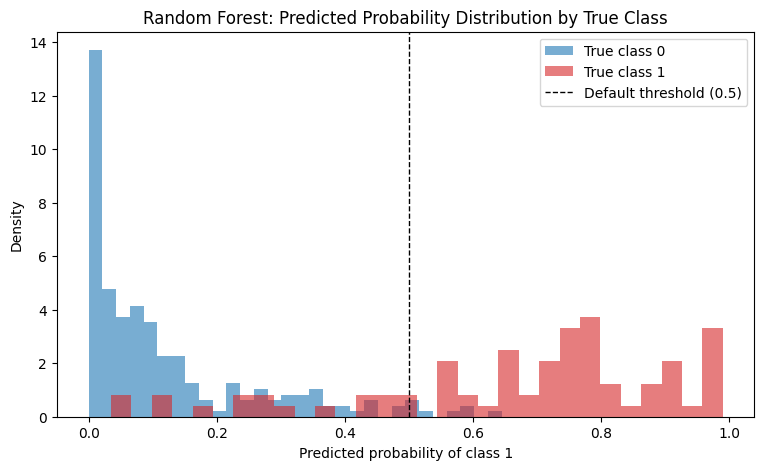

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(y_proba_rf[y_test == 0], bins=30, alpha=0.6, density=True, label="True class 0", color="tab:blue")
ax.hist(y_proba_rf[y_test == 1], bins=30, alpha=0.6, density=True, label="True class 1", color="tab:red")
ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Default threshold (0.5)")

ax.set_title("Random Forest: Predicted Probability Distribution by True Class")
ax.set_xlabel("Predicted probability of class 1")
ax.set_ylabel("Density")
ax.legend()
plt.show()


### Line-by-Line Explanation
- `y_proba_rf[y_test == 0]` / `[y_test == 1]` — NumPy boolean masking (a Chapter 1-era skill this course assumed you already had) splits the model's predicted probabilities into two groups based on the **true** label, letting you see whether the model's confidence scores actually separate the two classes.
- `density=True` — essential here since the two classes have different counts (imbalanced, per Chapter 51's setup); without it, the majority class's histogram would simply look taller for reasons unrelated to how well-separated the distributions are (the exact lesson from Chapter 19).
- `ax.axvline(0.5, ...)` — marks where the model's default hard-classification boundary sits, visually showing how many class-0 points get incorrectly pushed above it (false positives) and vice versa (false negatives).

### Interpretation
A well-performing model shows two clearly separated humps — true class-0 probabilities clustered near 0, true class-1 clustered near 1 — with minimal overlap. Substantial overlap directly around the 0.5 threshold line visually explains *why* the confusion matrix (next chapter) will show meaningful numbers of both false positives and false negatives, and is exactly the region a **threshold adjustment** (moving the cut point right or left) could rebalance.

### Common Mistakes
- Only ever looking at a single accuracy number and never this probability-distribution view — misses *why* a model makes the errors it does, and whether those errors are "confidently wrong" (worrying) or "barely wrong, right near the threshold" (often fine, sometimes fixable by threshold tuning alone).
- Forgetting `density=True` when comparing an imbalanced dataset's two class distributions, as flagged above.

### Best Practices
- Always inspect this probability-distribution-by-true-class view alongside (not instead of) the confusion matrix and ROC/PR curves — they answer different, complementary questions.
- Use the visible overlap region to motivate a business discussion about where the decision threshold should actually sit (Chapter 56 formalizes this into a full threshold-vs-metric sweep).

### Interview Insight
**Q: A classifier has 90% accuracy, but you're asked to also inspect its predicted-probability distribution split by true class. Why is that additional check worthwhile?**
A: Accuracy alone can't distinguish between a model that's confidently correct across the board versus one that's frequently borderline (probabilities clustered near the decision threshold) — the latter is much more fragile to threshold changes, class-imbalance shifts, or slight data drift in production, even at identical accuracy. The probability-distribution view surfaces that fragility directly, which a single summary metric cannot.

### Mini Exercise
Recreate this plot using `y_proba_lr` (the logistic regression model) instead of the random forest, and compare, in a markdown cell, whether the two classes appear more or less separated than for the random forest.

### Quiz (Chapter 52)
1. What does substantial overlap of the two class-probability histograms around the 0.5 line indicate?
2. Why is `density=True` essential here given the dataset's imbalance?
3. What complementary information does this chart provide beyond a single accuracy number?


---
# CHAPTER 53 — CONFUSION MATRIX FROM SCRATCH

## 1. Concept
A confusion matrix cross-tabulates **true label** vs **predicted label**, breaking a single accuracy number into its four constituent outcomes:

```
                 Predicted 0      Predicted 1
Actual 0            TN               FP
Actual 1            FN               TP
```

- **TN** (True Negative): correctly predicted negative
- **FP** (False Positive): incorrectly predicted positive ("false alarm")
- **FN** (False Negative): incorrectly predicted negative ("missed case")
- **TP** (True Positive): correctly predicted positive

## 2. Why It Matters
FP and FN often carry **very different real-world costs** (a missed fraud case vs. a false fraud alert; a missed cancer diagnosis vs. an unnecessary follow-up test) — a confusion matrix is the minimum level of detail needed to reason about that asymmetry, which a single accuracy number completely hides.


In [9]:
def compute_confusion_matrix(y_true, y_pred):
    """Build a 2x2 confusion matrix using only NumPy boolean masking."""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

cm_rf = compute_confusion_matrix(y_test, y_pred_rf)
print(cm_rf)


[[217   7]
 [ 17  59]]


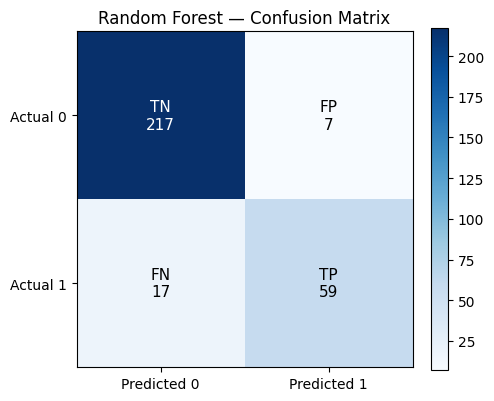

In [10]:
def plot_confusion_matrix(cm, class_names=("0", "1"), ax=None, title="Confusion Matrix"):
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4.5))
    else:
        fig = ax.get_figure()

    im = ax.imshow(cm, cmap="Blues", interpolation="nearest")   # nearest: discrete exact values (Ch 47's rule)
    fig.colorbar(im, ax=ax, fraction=0.046)

    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels([f"Predicted {c}" for c in class_names])
    ax.set_yticklabels([f"Actual {c}" for c in class_names])

    thresh = cm.max() / 2   # dynamic threshold for legible text color, same pattern as Ch 45/46
    labels = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]}", ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontsize=11)

    ax.set_title(title)
    return fig, ax

fig, ax = plot_confusion_matrix(cm_rf, title="Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `(y_true == 0) & (y_pred == 0)` — NumPy elementwise boolean AND across two boolean arrays; `np.sum()` on the result counts how many positions satisfy both conditions simultaneously — the core technique behind all four cell computations.
- The `plot_confusion_matrix()` function directly reuses Chapter 47's rule (`interpolation="nearest"` for exact discrete values) and Chapter 45/46's dynamic-threshold text-color pattern — this chapter is a direct synthesis of prior techniques applied to a new, ML-specific matrix.
- Returning `(fig, ax)` and accepting an optional `ax=` parameter follows the reusable-function signature convention established back in Chapter 3 and formalized in Chapter 86/87.

### Interpretation
Given the class imbalance (~25% positive, from Chapter 51's setup), look specifically at **FN** (missed true positives) relative to **TP** — this ratio is exactly what "recall" (Chapter 55) measures, and is often the single most business-critical number in an imbalanced classification problem (e.g., in fraud/churn/disease detection, a missed positive is frequently costlier than a false alarm).

### Common Mistakes
- Reading raw confusion matrix counts without normalizing by row (or knowing the class balance) — e.g., 50 false negatives sounds identical whether there were 60 or 6,000 actual positives, but the *rate* (recall) differs enormously; always view counts alongside the class totals.
- Building or interpreting the matrix with rows/columns transposed (true vs predicted swapped) — a very easy, very consequential mistake; always explicitly label both axes ("Actual" vs "Predicted") rather than assuming the reader (or your future self) will remember the convention.
- Applying interpolation smoothing (Chapter 47's warning, directly relevant here) — never smooth a confusion matrix's cells.

### Best Practices
- Always label both axes explicitly as "Actual" and "Predicted" — never leave this implicit.
- Consider a row-normalized (percentage) version alongside raw counts when class sizes are imbalanced, so FN/FP rates (not just raw counts) are directly visible.
- Build this as a reusable function (as done above) since every classification project needs one, often repeatedly across multiple models/thresholds.

### Interview Insight
**Q: Your model has 50 false negatives and 50 false positives — does that mean the two error types are equally costly or equally common relative to their class sizes?**
A: Not necessarily either. "Equally common in absolute count" says nothing about relative *rate* (50 FN out of 100 actual positives is a very different situation than 50 FN out of 5,000 actual positives), and absolute counts also say nothing about real-world *cost* — a false negative in fraud detection (a missed fraud case) is often far more expensive to the business than a false positive (an extra manual review), even at equal counts. Both the rate (normalized by class size) and the business cost of each error type need to be considered together, not inferred from raw counts alone.

### Mini Exercise
Extend `compute_confusion_matrix` conceptually (in a markdown cell, no need to fully code it) to describe how you'd generalize it to a **3-class** problem — what would change about the boolean-masking approach?

### Quiz (Chapter 53)
1. What do FP and FN each represent, in your own words?
2. Why is `interpolation="nearest"` (not smoothed) required for a confusion matrix?
3. Why can two confusion matrices with identical FN counts represent very different real-world severity?


---
# CHAPTER 54 — ROC CURVE

## 1. Concept
A **Receiver Operating Characteristic (ROC)** curve plots **True Positive Rate (TPR = Recall = TP/(TP+FN))** against **False Positive Rate (FPR = FP/(FP+TN))** as the classification threshold sweeps from 1 down to 0 — visualizing the full tradeoff between catching positives and generating false alarms, at every possible threshold simultaneously, rather than just the one implicit in `.predict()`.

## 2. Why It Matters
A single accuracy or confusion matrix reflects **one specific threshold** (usually 0.5); the ROC curve reveals the model's discriminative ability across **all** thresholds — letting you evaluate whether a model is fundamentally good at ranking positives above negatives, independent of any specific operating point you might later choose.


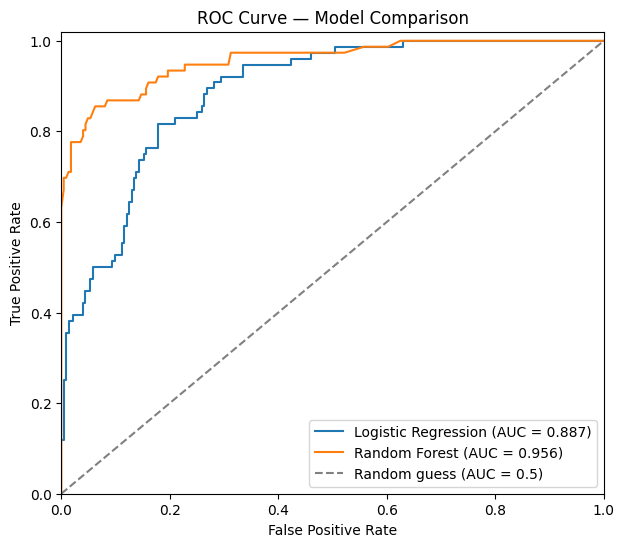

In [11]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr_lr, tpr_lr, thresholds_lr = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_proba_rf)

auc_lr = roc_auc_score(y_test, y_proba_lr)
auc_rf = roc_auc_score(y_test, y_proba_rf)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.3f})", color="tab:blue")
ax.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})", color="tab:orange")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess (AUC = 0.5)")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve — Model Comparison")
ax.legend(loc="lower right")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
plt.show()


### Line-by-Line / Parameter Explanation
- `roc_curve(y_test, y_proba_rf)` returns three arrays: `fpr`, `tpr` (one pair per distinct threshold in the data), and the `thresholds` themselves — internally, this function sweeps the threshold from the highest probability down to the lowest, recomputing the confusion matrix (and therefore TPR/FPR) at every distinct cutoff.
- The **diagonal reference line** (`[0,0]` to `[1,1]`) represents a model with **zero** discriminative ability — pure random guessing — and is a mandatory reference in every ROC plot; a curve that hugs this diagonal indicates a model barely better than chance.
- **AUC (Area Under the Curve)** — a single scalar summarizing the entire curve: `1.0` = perfect separation, `0.5` = random guessing, `<0.5` = worse than random (a red flag suggesting inverted predictions or a serious bug). AUC is threshold-independent, making it a fair way to compare two models' *overall* discriminative power before committing to any specific operating threshold.

### Internal Working
At each distinct probability value present in `y_proba`, `roc_curve()` treats that value as a candidate threshold, recomputes the resulting binary predictions (`proba >= threshold`), and derives TPR/FPR from the resulting confusion matrix — producing one `(FPR, TPR)` point per distinct threshold, which are then connected into the curve.

### Interpretation
The model whose curve bows further toward the **top-left corner** (high TPR at low FPR) is better — visually, "more area under the curve." Comparing the two models' AUC values directly answers "which model has fundamentally better ranking/discriminative ability," independent of which specific threshold either would eventually be deployed at.

### Common Mistakes
- Forgetting the diagonal reference line — without it, there's no visual baseline to judge "how much better than random" the curve actually is.
- Treating AUC as the single final word on model quality regardless of context — **AUC can be misleadingly optimistic under severe class imbalance** (Chapter 55 demonstrates exactly why Precision-Recall curves are often more informative in that specific situation).
- Computing ROC on the **training set** instead of a held-out test set — produces an overly optimistic curve reflecting overfitting rather than genuine generalization.

### Best Practices
- Always compute ROC/AUC on held-out test data, never training data.
- Always include the random-guess diagonal as a visual reference.
- Report AUC alongside the curve for a compact numeric summary, but never *instead of* the curve — the curve's shape (not just the scalar AUC) can reveal where in the threshold range a model is strong or weak.

### Interview Insight
**Q: Two models have nearly identical AUC (0.85 vs 0.84), but their ROC curves have visibly different shapes. Does the AUC alone tell you which to deploy?**
A: Not necessarily — AUC summarizes area across the *entire* threshold range, but a real deployment typically operates at one specific threshold (or narrow range) driven by business constraints (e.g., "we can only manually review 5% of flagged cases," which pins down a specific FPR). Two curves with similar AUC can differ substantially in TPR at the *specific* FPR you actually care about, so it's essential to inspect the curve's shape in the operationally relevant region, not just the single aggregate AUC number.

### Mini Exercise
Zoom the x-axis to `ax.set_xlim(0, 0.2)` (the low-false-positive-rate region, often the operationally relevant zone in fraud/security contexts) and compare which model actually has the higher TPR specifically in that narrow, business-relevant region — it may not be the model with the higher overall AUC.

### Quiz (Chapter 54)
1. What do the x-axis and y-axis of an ROC curve represent?
2. What does the diagonal reference line represent, and why is it mandatory?
3. What does an AUC below 0.5 suggest?
4. Why should ROC/AUC always be computed on held-out data?


---
# CHAPTER 55 — PRECISION-RECALL CURVE

## 1. Concept
A Precision-Recall (PR) curve plots **Precision (TP/(TP+FP))** against **Recall (TP/(TP+FN))** across all thresholds — the same threshold-sweeping idea as ROC (Chapter 54), but using two metrics that are both computed **only from the positive class's perspective**, unlike FPR (which depends on the — often much larger — negative class).

## 2. Why It Matters: PR vs ROC Under Class Imbalance
This is one of the most important, frequently-interview-tested distinctions in classification evaluation. Because FPR's denominator (`FP + TN`) is dominated by the (typically huge) negative class under imbalance, ROC curves can look deceptively strong even when a model's *precision* — how trustworthy a positive prediction actually is — is poor. PR curves, having no dependence on `TN` at all, are far more sensitive to exactly this failure mode.


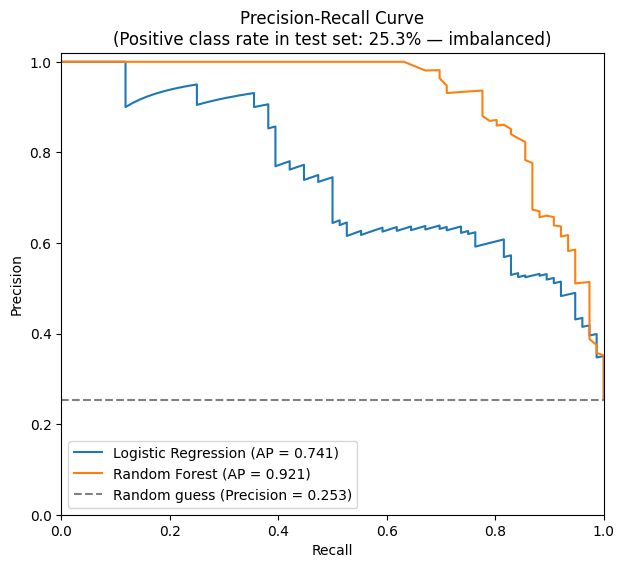

In [12]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_proba_lr)
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_proba_rf)

ap_lr = average_precision_score(y_test, y_proba_lr)
ap_rf = average_precision_score(y_test, y_proba_rf)

baseline = y_test.mean()   # a "random" classifier's precision equals the positive class rate

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall_lr, precision_lr, label=f"Logistic Regression (AP = {ap_lr:.3f})", color="tab:blue")
ax.plot(recall_rf, precision_rf, label=f"Random Forest (AP = {ap_rf:.3f})", color="tab:orange")
ax.axhline(baseline, linestyle="--", color="gray", label=f"Random guess (Precision = {baseline:.3f})")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(f"Precision-Recall Curve\n(Positive class rate in test set: {baseline:.1%} — imbalanced)")
ax.legend(loc="lower left")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
plt.show()


### Line-by-Line / Parameter Explanation
- `precision_recall_curve()` — same threshold-sweeping mechanism as `roc_curve()` (Chapter 54), but returns `(precision, recall)` pairs instead of `(fpr, tpr)`.
- **Baseline reference line**: unlike ROC's fixed 0.5-AUC diagonal, a "random" classifier's PR baseline equals the **positive class rate itself** (here, ~25%) — a *horizontal* line, not a diagonal — and this baseline **shifts** depending on class balance, which is itself an important, often-tested conceptual distinction from ROC's fixed baseline.
- **Average Precision (AP)** — the PR-curve analogue of ROC-AUC: a single scalar summarizing the curve (specifically, the weighted mean of precision achieved at each threshold, weighted by the increase in recall).

### Why PR Beats ROC Specifically Under Imbalance — the Core Lesson
Recall this notebook's test set is ~25% positive (Chapter 51 setup). Because ROC's FPR denominator includes the large negative class (`TN` dwarfs `FP` numerically when negatives are the majority), even a model producing a meaningful number of false positives can show a *deceptively low* FPR simply because the negative class is so large — making the ROC curve look strong. Precision (`TP/(TP+FP)`), having **no** `TN` term at all, is directly and sharply sensitive to exactly this false-positive problem, which is precisely why PR curves are the standard recommendation for imbalanced classification problems (fraud, rare disease detection, security threats) where **false positives are common in absolute terms even when they're a "small percentage" of the huge negative class**.

### Interpretation
Compare each model's AP to the baseline (~25%) — a model meaningfully above baseline across most of the recall range is demonstrating real value specifically at *making positive predictions worth trusting* (precision), not just at avoiding a large sea of true negatives (which is comparatively easy in an imbalanced setting and is what inflates ROC-AUC).

### Common Mistakes
- Reporting only ROC-AUC for an imbalanced classification problem (fraud, churn, rare disease) without also showing the PR curve — a very common, real-world evaluation mistake that can make a genuinely weak (low-precision) model look deceptively strong.
- Forgetting that the PR baseline is the **positive class rate**, not a fixed 0.5 or a diagonal — a common conceptual confusion when moving from ROC to PR curves.
- Comparing AP scores across datasets/problems with *different* class balances as if they were directly comparable — AP's baseline (and therefore its interpretation) shifts with the positive class rate, unlike ROC-AUC's fixed 0.5 baseline.

### Best Practices
- For any classification problem with meaningful class imbalance (a common rule of thumb: minority class under ~20–30%), report and visualize **both** ROC and PR curves — never PR-only or ROC-only as the sole evaluation artifact.
- Always plot the correct baseline reference for whichever curve you're showing (diagonal for ROC, horizontal positive-rate line for PR) — and always state the class balance explicitly in the chart title/caption, since it directly affects how the PR baseline should be read.

### Interview Insight
**Q: Why might a fraud-detection model with a strong (0.95) ROC-AUC still be genuinely unreliable in production, and how would you catch this before deployment?**
A: Fraud datasets are typically severely imbalanced (fraud might be <1% of transactions), so ROC's FPR term is dominated by the enormous negative (non-fraud) class — a model can generate a large *absolute* number of false positives (e.g., flagging thousands of legitimate transactions) while still showing a tiny FPR and a strong-looking ROC-AUC, because that FPR is measured against an enormous denominator. Checking the Precision-Recall curve and Average Precision score specifically — which have no `TN` term — would expose this weakness directly, since a high false-positive count relative to true positives shows up immediately as low precision, which ROC-AUC can mask under severe imbalance.

### Mini Exercise
Compute and print `y_test.mean()` again explicitly, and confirm it matches the `baseline` horizontal line plotted above — then explain, in a markdown cell, why this specific value (and not 0.5) is the correct "random guess" reference for a PR curve.

### Quiz (Chapter 55)
1. What's the key structural difference between ROC's FPR and PR's Precision that makes PR more sensitive to class imbalance?
2. What determines a PR curve's baseline reference line, and how does that differ from ROC's baseline?
3. In what specific type of real-world problem should you always check the PR curve alongside (or instead of relying solely on) ROC-AUC?

### Chapter 55 Summary
- ROC and PR curves both sweep every possible classification threshold, but weight the negative class very differently — ROC through FPR (denominator includes TN), PR through Precision (no TN term at all).
- Under class imbalance, ROC-AUC can look deceptively strong while PR/AP reveals a genuinely weak, low-precision model — always check both for imbalanced problems.

---

## END OF NOTEBOOK 6 — What You Should Now Be Able To Do
- Build heatmaps and general matrix/image visualizations correctly, choosing the right colormap type, interpolation setting, and origin.
- Attach a properly-labeled colorbar to any continuous color encoding, as a mandatory (not optional) step.
- Build contour/filled-contour plots from a `meshgrid`-evaluated function, and connect this directly to visualizing a classifier's decision boundary.
- Know precisely when 3D visualization helps versus when a 2D alternative (contour, or color/size-encoded scatter) is more honest and readable.
- Train real scikit-learn classifiers and extract the `predict_proba()` output required for every threshold-based ML visualization.
- Build a confusion matrix entirely from scratch using NumPy boolean masking, and correctly interpret TP/TN/FP/FN in a business-cost context.
- Build, read, and compare ROC curves and AUC across models.
- Build, read, and compare Precision-Recall curves and Average Precision — and explain precisely why they matter more than ROC under class imbalance, a very common interview question.

## Before Moving to Notebook 7 (Chapters 56–65: Threshold Visualization, Regression Model Visualization, Residual Analysis, Feature Importance, Model Comparison, Hyperparameter Visualization, Learning Curves, Validation Curves, Experiment Visualization, Error Analysis) 
